# Exploratory Data Analysis

#### Roles to Explore:

In [19]:
#Importing Libraries
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
import seaborn as sms

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

### Filter for US Data Analyst Roles

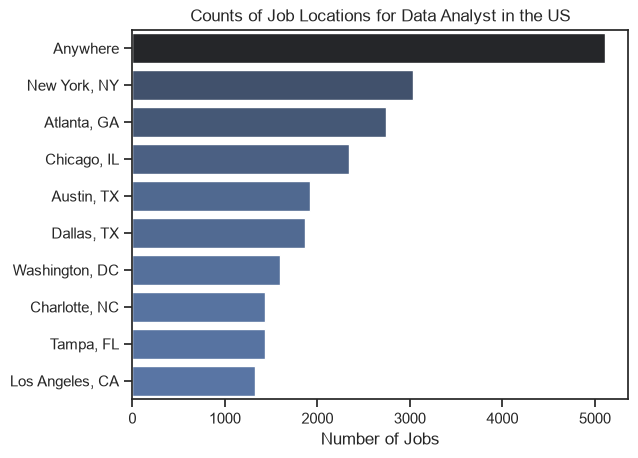

In [ ]:
df_DA_US = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'United States')]

df_plot = df_DA_US['job_location'].value_counts().head(10).to_frame()

sms.set_theme(style='ticks')
sms.barplot(data=df_plot, x='count', y='job_location', hue='count', palette='dark:b_r', legend=False)

plt.title('Counts of Job Locations for Data Analyst in the US')
plt.xlabel('Number of Jobs')
plt.ylabel('')
plt.show()

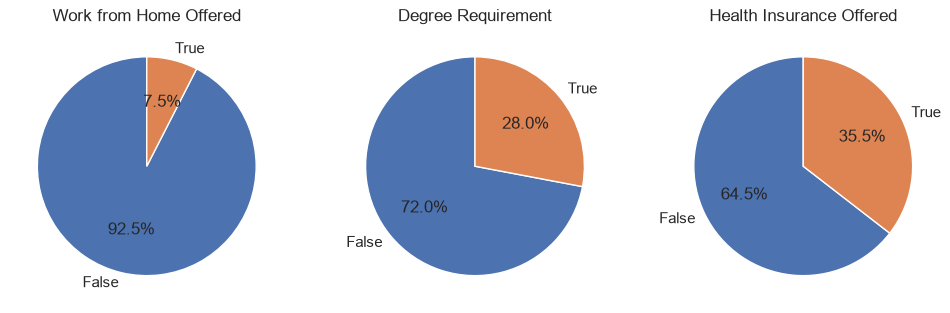

In [26]:

dict_column = {
  'job_work_from_home' : 'Work from Home Offered',
  'job_no_degree_mention' : 'Degree Requirement',
  'job_health_insurance' : 'Health Insurance Offered'
}

fig, ax = plt.subplots(1, 3)
fig.set_size_inches((12, 5))

for i, (column, title) in enumerate(dict_column.items()):
  ax[i].pie(df_DA_US[column].value_counts(), startangle=90, autopct='%1.1f%%', labels=['False', 'True'])
  ax[i].set_title(title)
  
plt.show()

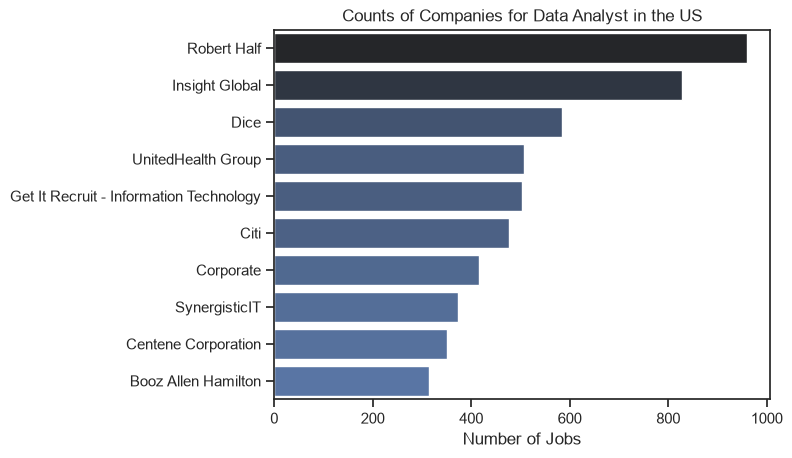

In [27]:
df_DA_US = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'United States')]

df_plot = df_DA_US['company_name'].value_counts().head(10).to_frame()

sms.set_theme(style='ticks')
sms.barplot(data=df_plot, x='count', y='company_name', hue='count', palette='dark:b_r', legend=False)

plt.title('Counts of Companies for Data Analyst in the US')

plt.xlabel('Number of Jobs')
plt.ylabel('')
plt.show()